# Actividad 2 - Modelo Baseline y MLflow Tracking

**Curso:** TC5061  
**Actividad:** Flujo básico de modelado en Machine Learning  
**Dataset:** Car Evaluation - UCI Machine Learning Repository  
**Alumno:** Andrea Paola Martínez López
**Fecha:** 04/10/2026

## Objetivo

Desarrollar un flujo básico y reproducible de Machine Learning utilizando
el dataset Car Evaluation. Se realizará la exploración y limpieza de los
datos, el entrenamiento de un modelo baseline de clasificación, su
evaluación y el registro del experimento mediante MLflow Tracking.

El objetivo del modelo es predecir el nivel de aceptabilidad de un
automóvil a partir de variables relacionadas con su precio, mantenimiento,
capacidad, características y seguridad.

In [1]:
# Instalar MLflow en el entorno de Colab
!pip install -q mlflow

# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Evaluación
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# MLflow
import mlflow
import mlflow.sklearn

# Configuración para reproducibilidad
RANDOM_STATE = 42

import sklearn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Cargar data set


In [38]:
import zipfile

columnas = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

with zipfile.ZipFile("car+evaluation.zip", "r") as archivo_zip:
    with archivo_zip.open("car.data") as archivo:
        df = pd.read_csv(
            archivo,
            header=None,
            names=columnas
        )

df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## EDA
1,728 observaciones
7 columnas

In [3]:
print("Dimensiones del dataset:", df.shape)

Dimensiones del dataset: (1728, 7)


In [4]:
df.head(10)

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
5,vhigh,vhigh,2,2,med,high,unacc
6,vhigh,vhigh,2,2,big,low,unacc
7,vhigh,vhigh,2,2,big,med,unacc
8,vhigh,vhigh,2,2,big,high,unacc
9,vhigh,vhigh,2,4,small,low,unacc


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1728 non-null   str  
 1   maint     1728 non-null   str  
 2   doors     1728 non-null   str  
 3   persons   1728 non-null   str  
 4   lug_boot  1728 non-null   str  
 5   safety    1728 non-null   str  
 6   class     1728 non-null   str  
dtypes: str(7)
memory usage: 133.5 KB


In [6]:
df.nunique()

buying      4
maint       4
doors       4
persons     3
lug_boot    3
safety      3
class       4
dtype: int64

In [7]:
for columna in df.columns:
    print(f"{columna}: {df[columna].unique()}")

buying: <ArrowStringArray>
['vhigh', 'high', 'med', 'low']
Length: 4, dtype: str
maint: <ArrowStringArray>
['vhigh', 'high', 'med', 'low']
Length: 4, dtype: str
doors: <ArrowStringArray>
['2', '3', '4', '5more']
Length: 4, dtype: str
persons: <ArrowStringArray>
['2', '4', 'more']
Length: 3, dtype: str
lug_boot: <ArrowStringArray>
['small', 'med', 'big']
Length: 3, dtype: str
safety: <ArrowStringArray>
['low', 'med', 'high']
Length: 3, dtype: str
class: <ArrowStringArray>
['unacc', 'acc', 'vgood', 'good']
Length: 4, dtype: str


## Descripción del conjunto de datos

El conjunto de datos contiene 1,728 registros y siete columnas.
Seis variables corresponden a características utilizadas para evaluar
los automóviles y una corresponde a la variable objetivo (`class`).

Las variables son de naturaleza categórica. El problema corresponde a
una clasificación multiclase, debido a que la variable objetivo presenta
cuatro categorías: `unacc`, `acc`, `good` y `vgood`.

Las variables predictoras describen el precio de compra, costo de
mantenimiento, número de puertas, capacidad de pasajeros, tamaño del
maletero y nivel de seguridad del vehículo.

In [8]:
# Para variables categóricas se utiliza describe() en lugar de mean()
df.describe(include="all").T

,count,unique,top,freq
buying,1728,4,vhigh,432
maint,1728,4,vhigh,432
doors,1728,4,2,432
persons,1728,3,2,576
lug_boot,1728,3,small,576
safety,1728,3,low,576
class,1728,4,unacc,1210


In [9]:
distribucion_clases = pd.DataFrame({
    "Cantidad": df["class"].value_counts(),
    "Porcentaje": df["class"].value_counts(normalize=True) * 100
})

distribucion_clases.round(2)

,Cantidad,Porcentaje
class,,
unacc,1210,70.02
acc,384,22.22
good,69,3.99
vgood,65,3.76


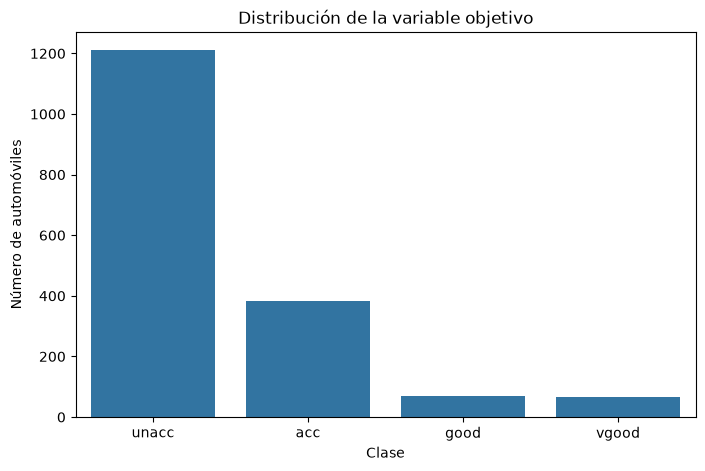

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="class",
    order=["unacc", "acc", "good", "vgood"]
)

plt.title("Distribución de la variable objetivo")
plt.xlabel("Clase")
plt.ylabel("Número de automóviles")
plt.show()

### Interpretación

La distribución de la variable objetivo muestra un desbalance importante
entre las clases. Aproximadamente el 70% de los registros pertenece a la
categoría `unacc`, mientras que las clases `good` y `vgood` representan
aproximadamente el 4% cada una.

Este comportamiento debe considerarse durante la división y evaluación
del modelo, ya que una métrica como accuracy podría estar influenciada
por la clase mayoritaria. Por esta razón, además de accuracy se utilizará
F1-score macro, que asigna la misma importancia a cada una de las clases.

In [11]:
tabla_safety = pd.crosstab(
    df["safety"],
    df["class"],
    normalize="index"
) * 100

tabla_safety.round(2)

class,acc,good,unacc,vgood
safety,,,,
high,35.42,5.21,48.09,11.28
low,0.00,0.00,100.00,0.00
med,31.25,6.77,61.98,0.00


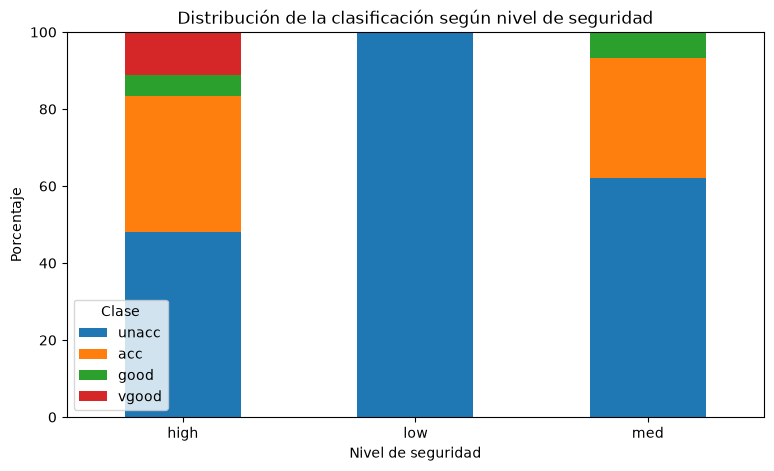

In [12]:
orden_clases = ["unacc", "acc", "good", "vgood"]

tabla_safety[orden_clases].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Distribución de la clasificación según nivel de seguridad")
plt.xlabel("Nivel de seguridad")
plt.ylabel("Porcentaje")
plt.legend(title="Clase")
plt.xticks(rotation=0)
plt.show()

In [13]:
tabla_persons = pd.crosstab(
    df["persons"],
    df["class"],
    normalize="index"
) * 100

tabla_persons.round(2)

class,acc,good,unacc,vgood
persons,,,,
2,0.00,0.00,100.00,0.00
4,34.38,6.25,54.17,5.21
more,32.29,5.73,55.90,6.08


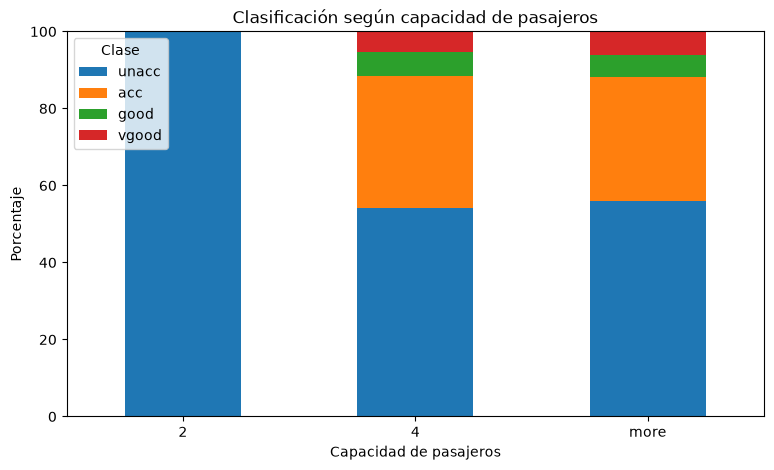

In [14]:
tabla_persons[orden_clases].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Clasificación según capacidad de pasajeros")
plt.xlabel("Capacidad de pasajeros")
plt.ylabel("Porcentaje")
plt.legend(title="Clase")
plt.xticks(rotation=0)
plt.show()

La capacidad de pasajeros muestra una relación clara con la variable
objetivo. Los vehículos cuya capacidad es únicamente de dos personas
son clasificados como `unacc` en todos los registros del dataset.
Esto indica que la capacidad del automóvil puede ser una variable
relevante para el proceso de clasificación.

In [15]:
tabla_buying = pd.crosstab(
    df["buying"],
    df["class"],
    normalize="index"
) * 100

tabla_buying.round(2)

class,acc,good,unacc,vgood
buying,,,,
high,25.00,0.00,75.00,0.00
low,20.60,10.65,59.72,9.03
med,26.62,5.32,62.04,6.02
vhigh,16.67,0.00,83.33,0.00


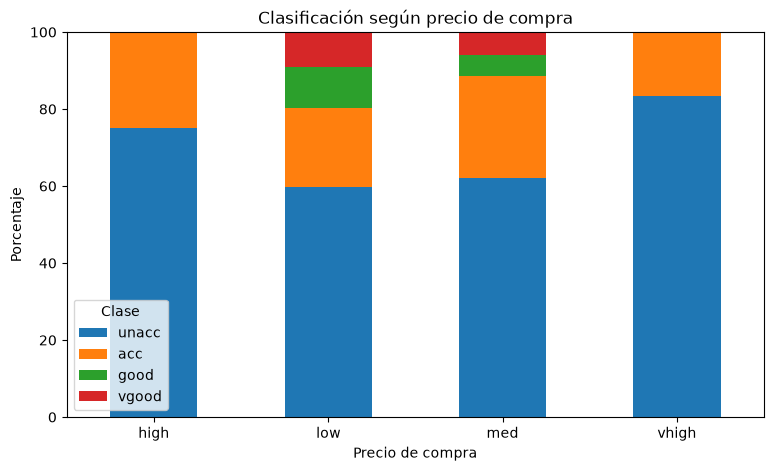

In [16]:
tabla_buying[orden_clases].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Clasificación según precio de compra")
plt.xlabel("Precio de compra")
plt.ylabel("Porcentaje")
plt.legend(title="Clase")
plt.xticks(rotation=0)
plt.show()

### Conclusiones del análisis exploratorio

El análisis exploratorio permitió identificar un importante desbalance
en la variable objetivo, donde la categoría `unacc` representa alrededor
del 70% de los registros.

También se observaron relaciones claras entre algunas características
y la clasificación final. Por ejemplo, todos los automóviles con nivel
de seguridad `low` fueron clasificados como `unacc`. De manera similar,
los vehículos con capacidad para únicamente dos personas también
pertenecen completamente a la clase `unacc`.

El precio de compra también muestra relación con la clasificación:
los vehículos con precios muy altos presentan una mayor proporción de
clasificaciones no aceptables, mientras que las categorías `good` y
`vgood` aparecen con mayor frecuencia en vehículos con precios menores.

Estos resultados sugieren que variables como seguridad, capacidad y
precio pueden ser particularmente relevantes para el modelo de
clasificación.

### Valores faltantes

No se encontraron valores faltantes en ninguna de las variables del
dataset. Por esta razón no fue necesario aplicar técnicas de imputación
ni eliminar observaciones.

In [17]:
duplicados = df.duplicated().sum()

print("Registros duplicados:", duplicados)

Registros duplicados: 0


### Registros duplicados

Se verificó la existencia de registros duplicados mediante `duplicated()`.
No se encontraron observaciones duplicadas, por lo que no fue necesario
eliminar registros.

## Limpieza de datos

In [18]:
for columna in df.columns:
    df[columna] = df[columna].astype(str).str.strip()

## Validar categorias

In [19]:
categorias_validas = {
    "buying": {"vhigh", "high", "med", "low"},
    "maint": {"vhigh", "high", "med", "low"},
    "doors": {"2", "3", "4", "5more"},
    "persons": {"2", "4", "more"},
    "lug_boot": {"small", "med", "big"},
    "safety": {"low", "med", "high"},
    "class": {"unacc", "acc", "good", "vgood"}
}

for columna, permitidos in categorias_validas.items():

    encontrados = set(df[columna].unique())

    invalidos = encontrados - permitidos

    print(f"{columna} -> valores inválidos: {invalidos}")

buying -> valores inválidos: set()
maint -> valores inválidos: set()
doors -> valores inválidos: set()
persons -> valores inválidos: set()
lug_boot -> valores inválidos: set()
safety -> valores inválidos: set()
class -> valores inválidos: set()


## outliers
### Valores atípicos

Debido a que todas las variables del conjunto de datos son categóricas,
los métodos tradicionales para detección de outliers numéricos, como
IQR o Z-score, no son aplicables.

En su lugar, se realizó una validación de dominio comprobando que cada
variable solamente contuviera las categorías definidas originalmente
para el dataset. No se detectaron categorías inválidas ni valores fuera
del dominio esperado.

In [20]:
for columna in df.columns:
    df[columna] = df[columna].astype("category")

df.dtypes

buying      category
maint       category
doors       category
persons     category
lug_boot    category
safety      category
class       category
dtype: object

### Resultado de la limpieza

El dataset presenta una calidad alta. No se identificaron valores
faltantes ni registros duplicados. Asimismo, se validaron las categorías
permitidas para cada variable y no se encontraron valores fuera del
dominio esperado.

Debido a la naturaleza categórica de todas las variables, no se aplicaron
métodos de detección de outliers numéricos. Finalmente, las columnas se
convirtieron al tipo `category` para representar correctamente su
naturaleza conceptual.

Por lo tanto, no fue necesario eliminar ni imputar observaciones.

# Definir X e y

In [21]:
X = df.drop(columns="class")
y = df["class"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

In [23]:
print("Registros entrenamiento:", len(X_train))
print("Registros prueba:", len(X_test))

Registros entrenamiento: 1382
Registros prueba: 346


In [24]:
print("Distribución entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribución prueba:")
print(y_test.value_counts(normalize=True).round(3))

Distribución entrenamiento:
class
unacc    0.700
acc      0.222
good     0.040
vgood    0.038
Name: proportion, dtype: float64

Distribución prueba:
class
unacc    0.699
acc      0.223
good     0.040
vgood    0.038
Name: proportion, dtype: float64


In [25]:
variables_categoricas = X.columns.tolist()

preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        )
    ]
)

# Modelo baseline, Regresión Logística

In [26]:
modelo_baseline = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                solver="lbfgs",
                C=1.0
            )
        )
    ]
)

# Entrenar

In [27]:
modelo_baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['acc','good','unacc','vgood']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['buying','maint','doors','persons','lug_boot','safety']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

# Predicciones

In [28]:
y_pred = modelo_baseline.predict(X_test)

In [29]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9017


**Aproximadamente 9 de cada 10 automóviles del conjunto de prueba fueron clasificados correctamente.**

In [30]:
f1_macro = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print(f"F1-macro: {f1_macro:.4f}")

F1-macro: 0.7873


In [31]:
print(
    classification_report(
        y_test,
        y_pred,
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         acc      0.772     0.792     0.782        77
        good      0.636     0.500     0.560        14
       unacc      0.959     0.963     0.961       242
       vgood      0.846     0.846     0.846        13

    accuracy                          0.902       346
   macro avg      0.803     0.775     0.787       346
weighted avg      0.900     0.902     0.901       346



# Matriz de confusion

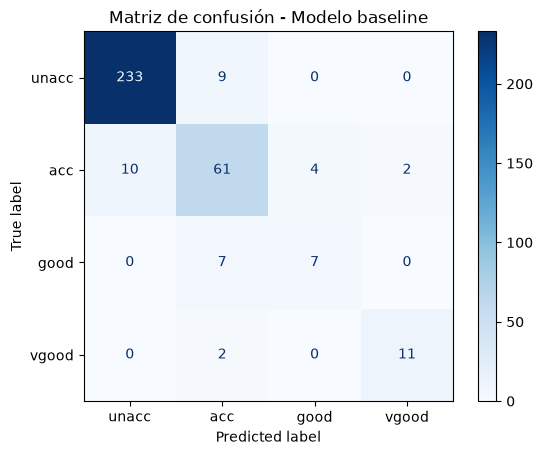

In [32]:
orden_clases = ["unacc", "acc", "good", "vgood"]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=orden_clases,
    cmap="Blues"
)

plt.title("Matriz de confusión - Modelo baseline")
plt.show()

## Interpretación del modelo baseline

El modelo baseline obtuvo una accuracy cercana al 90%, lo que indica
que aproximadamente nueve de cada diez registros del conjunto de prueba
fueron clasificados correctamente.

Sin embargo, debido al desbalance existente en la variable objetivo,
accuracy no debe analizarse de forma aislada. La clase `unacc`
representa aproximadamente el 70% de los datos, por lo que el desempeño
sobre esta clase puede influir considerablemente en la métrica global.

Por esta razón también se calculó F1-score macro, el cual considera
por igual el desempeño de cada una de las cuatro clases. El resultado
es menor que la accuracy general, mostrando que existen diferencias
entre el desempeño obtenido para las clases mayoritarias y minoritarias.

El reporte de clasificación muestra que la clase `unacc` presenta el
mejor desempeño, mientras que `good` resulta más difícil de identificar,
lo que puede estar relacionado con el reducido número de observaciones
disponibles para esta categoría.

El modelo constituye un punto de partida adecuado sobre el cual podrían
evaluarse posteriormente otras estrategias de modelado y tratamiento
del desbalance.

In [33]:
# Usar una base de datos SQLite local para el tracking de MLflow (evita el error de sistema de archivos)
mlflow.set_tracking_uri("sqlite:///mlflow.db")

mlflow.set_experiment(
    "TC5061_Car_Evaluation_Baseline"
)

print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: sqlite:///mlflow.db


In [34]:
parametros = {
    "modelo": "LogisticRegression",
    "solver": "lbfgs",
    "C": 1.0,
    "max_iter": 1000,
    "test_size": 0.20,
    "random_state": RANDOM_STATE,
    "encoding": "OneHotEncoder"
}

In [35]:
datos_train_mlflow = X_train.copy()
datos_train_mlflow["class"] = y_train.values

dataset_train = mlflow.data.from_pandas(
    datos_train_mlflow,
    name="car_evaluation_train",
    targets="class"
)

2026/10/04 21:44:18 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/10/04 21:44:18 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

In [36]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")

print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: http://127.0.0.1:5000


In [37]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

for experimento in client.search_experiments():
    print(
        experimento.experiment_id,
        experimento.name
    )

1 TC5061_Car_Evaluation_Baseline
0 Default
